In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from marathon_predictor.baseline import riegel_predict
from marathon_predictor.config import PROCESSED_DIR, SPLITS_KM

In [3]:
df = pd.read_parquet(PROCESSED_DIR / "berlin.parquet")
df.head()

,year,gender,nationality,split_5k,split_10k,split_15k,split_20k,time_half,split_25k,split_30k,split_35k,split_40k,time_full
0,1999,M,KEN,909.0,1821.0,2725.0,3634.0,3834.0,4494.0,5410.0,6305.0,7208.0,7604.0
1,1999,M,JPN,909.0,1821.0,2727.0,3636.0,3834.0,4496.0,5418.0,6321.0,7218.0,7617.0
2,1999,M,KEN,910.0,1821.0,2727.0,3635.0,3834.0,4495.0,5418.0,6359.0,7301.0,7711.0
3,1999,M,MAR,911.0,1823.0,2727.0,3636.0,3835.0,4496.0,5424.0,6374.0,7372.0,7796.0
4,1999,M,KEN,910.0,1821.0,NaN,3635.0,3835.0,4495.0,5418.0,6374.0,7378.0,7837.0


In [4]:
train = df[df["year"] <= 2017]
test = df[df["year"] > 2017]

In [28]:
def evaluate_riegel(data: pd.DataFrame, exponent=1.06) -> pd.DataFrame:
    rows = []
    for col, km in SPLITS_KM.items():
        if col == "time_full":
            continue
        prediction = riegel_predict(data[col], km, exponent=exponent)
        error = prediction - data["time_full"]
        rel_error = error / data["time_full"]
        rows.append(
            {
                "split": col,
                "km": km,
                "mae_min": error.abs().mean() / 60,
                "mape": rel_error.abs().mean() * 100,
                "bias_min": error.mean() / 60,
            }
        )
    results = pd.DataFrame(rows)
    return results

In [29]:
results_riegel = evaluate_riegel(test, exponent=1.06)
results_even = evaluate_riegel(test, exponent=1)
results_riegel, results_even

(       split       km    mae_min      mape   bias_min
 0   split_5k   5.0000  21.184739  8.643651  13.986551
 1  split_10k  10.0000  15.202303  6.005743   5.051804
 2  split_15k  15.0000  12.389528  4.763668  -0.035202
 3  split_20k  20.0000  10.551326  3.980715  -2.932123
 4  time_half  21.0975  10.246578  3.849761  -3.561040
 5  split_25k  25.0000   8.588101  3.230471  -3.583117
 6  split_30k  30.0000   6.152912  2.334028  -2.768105
 7  split_35k  35.0000   3.702416  1.412502  -1.846911
 8  split_40k  40.0000   1.090338  0.422397   0.151219,
        split       km    mae_min      mape   bias_min
 0   split_5k   5.0000  19.763507  7.020244 -18.335881
 1  split_10k  10.0000  17.661708  6.330643 -16.476534
 2  split_15k  15.0000  16.288226  5.866478 -15.381349
 3  split_20k  20.0000  14.671191  5.322745 -13.977722
 4  time_half  21.0975  14.425093  5.243542 -13.807018
 5  split_25k  25.0000  11.956979  4.381395 -11.358817
 6  split_30k  30.0000   8.425558  3.134516  -7.879456
 7  split

The bias of the Riegel prediction changes sign over the course of the race. For early splits (5k, 10k), Riegel is too pessimistic (bias +14 and +5 min): the first kilometres of a crowded city marathon are slowed down by congestion, and the formula additionally assumes a large slowdown when extrapolating from a short distance (factor ≈ 1.14 from 5k). From around 20k onwards, Riegel becomes too optimistic (bias ≈ −3.5 min): many runners slow down more in the second half than the formula’s factor of ≈ 1.04 from the half split assumes, which matches the EDA finding that 38% of runners were more than 10% slower in the second half. One reason might be that Riegel’s formula was designed to predict times across separate races with fresh legs, not to extrapolate from split times within the same race.

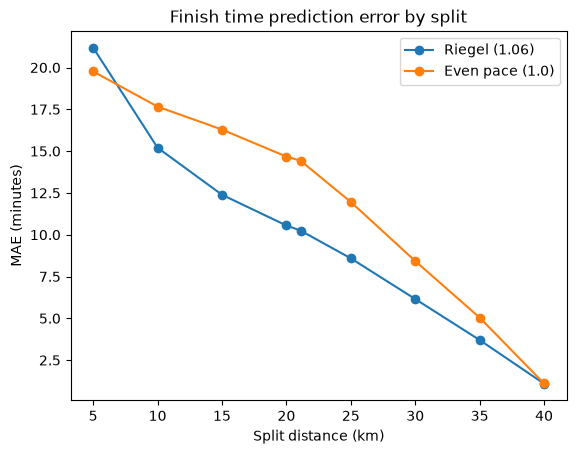

In [25]:
ax = results_riegel.plot(x="km", y="mae_min", marker="o", label="Riegel (1.06)")
results_even.plot(x="km", y="mae_min", marker="o", label="Even pace (1.0)", ax=ax)

ax.set_xlabel("Split distance (km)")
ax.set_ylabel("MAE (minutes)")
ax.set_title("Finish time prediction error by split")
plt.show()

You can clearly see that the MAE decreases as the distance increases since the prediction gets easier. The "Riegel"-exponent of 1.06 is still better for forecasting finish times than using 1.0 as an exponent. At the split 5k, the exponent of 1.0 is better at predicting the finish-time. However, this could have been caused by the same reasons as mentioned above. 